# Corn, soybeans, and river-flood exposure near the Des Moines River

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RiskThinking/crc-docs/blob/main/notebooks/sources/agricultural_climate_risk.ipynb) · [GitHub preview](https://github.com/RiskThinking/crc-docs/blob/main/notebooks/sources/agricultural_climate_risk.ipynb)

This practical sourcing screen combines **2025 USDA Cropland Data Layer** pixels with a bounded, canonical **JRC GloFAS riverine-flood hazard**. The question is intentionally narrow: *which sampled corn and soybean H3 units overlap modeled flood depths, and how does that overlap change from a 10-year to a 100-year event?*

The workflow never downloads a national crop raster or a global flood layer. Icechunk supplies bounded Arrow batches; DuckDB aggregates them out of core; only the small result is materialized. Crop pixels are evidence of land cover—not acreage, yield, ownership, or vulnerability—and flood depth remains a separate hazard measurement rather than a synthetic risk score.

**Workflow:** [Python pipeline](https://github.com/RiskThinking/crc-docs/blob/main/pipelines/agricultural_climate_pipeline.py) · [Question-driven examples](https://github.com/RiskThinking/crc-docs#pick-a-question)


## Run the notebook

In Colab, choose **Runtime → Run all**. The setup cell installs the required
packages and downloads any small repository files used by the analysis.


In [1]:
#@title Install dependencies and prepare this notebook
import hashlib
import importlib
import importlib.metadata
import importlib.util
import os
from pathlib import Path
import subprocess
import sys
import sysconfig
import urllib.request

if sys.version_info < (3, 12):
    raise RuntimeError("Use a Python 3.12+ runtime (Colab: Runtime > Change runtime type).")

# Install into this kernel's Python, not a separate shell environment.
REQUIREMENTS = ['crc-sdk[agriculture,geometry,raster]==0.7.1', 'crc-framework==0.2.5', 'duckdb>=1.4.5,<2', 'numpy>=1.26,<3', 'pandas>=2.2,<4', 'plotly==6.9.0', 'nbformat>=5.10,<6', 'tippecanoe==2.72.0']
loaded_versions = {
    module: getattr(sys.modules[module], "__version__", None)
    for module in ("numpy", "pandas", "pyarrow", "plotly", "duckdb", "crc_sdk", "crc_framework")
    if module in sys.modules
}
if importlib.util.find_spec("pip") is None:
    subprocess.check_call([sys.executable, "-m", "ensurepip", "--upgrade"])
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "--quiet", "--disable-pip-version-check",
    *REQUIREMENTS,
])
importlib.invalidate_caches()
for module, loaded in loaded_versions.items():
    installed = importlib.metadata.version(module.replace("_", "-"))
    if loaded is not None and loaded != installed:
        raise RuntimeError("Packages changed after import. Restart the kernel/session, then run all cells again.")
os.environ["PATH"] = sysconfig.get_path("scripts") + os.pathsep + os.environ.get("PATH", "")
IN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False

# A local checkout keeps its files; standalone/Colab runs download only required resources.
RESOURCE_REVISION = '52ff7a93028cc1e64f3b1df856851650df825dc8'
RESOURCE_SHA256 = {'pipelines/agricultural_climate_pipeline.py': 'f2095a1e5fea26baedf63f73a863d988dea29a09615f0e409c5f591cd239e6d1'}
REPO_ROOT = next((
    folder for folder in (Path.cwd(), *Path.cwd().parents)
    if (folder / "pyproject.toml").is_file()
    and 'name = "crc-docs"' in (folder / "pyproject.toml").read_text()
), None)
if REPO_ROOT is None:
    REPO_ROOT = next((
        folder for folder in (Path.cwd(), *Path.cwd().parents)
        if (folder / ".crc-notebook-revision").is_file()
        and (folder / ".crc-notebook-revision").read_text() == RESOURCE_REVISION
    ), Path.cwd() / ".crc-docs" / RESOURCE_REVISION)
    REPO_ROOT.mkdir(parents=True, exist_ok=True)
    (REPO_ROOT / ".crc-notebook-revision").write_text(RESOURCE_REVISION)
    for relative, expected_hash in RESOURCE_SHA256.items():
        target = REPO_ROOT / relative
        if not target.exists() or hashlib.sha256(target.read_bytes()).hexdigest() != expected_hash:
            url = f"https://raw.githubusercontent.com/RiskThinking/crc-docs/{RESOURCE_REVISION}/{relative}"
            with urllib.request.urlopen(url, timeout=120) as response:
                content = response.read()
            if hashlib.sha256(content).hexdigest() != expected_hash:
                raise RuntimeError(f"Resource checksum mismatch: {relative}")
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_bytes(content)
NOTEBOOK_DIR = REPO_ROOT / "notebooks"
NOTEBOOK_DIR.mkdir(parents=True, exist_ok=True)
os.chdir(NOTEBOOK_DIR)

print(f"Ready: Python {sys.version.split()[0]}, crc-sdk {importlib.metadata.version('crc-sdk')}")
print(f"Working directory: {NOTEBOOK_DIR}")


Looking in links: /var/folders/x_/2g1bv3nn6mqfkfmnk272wcsr0000gn/T/tmpwaek1k19
Processing /var/folders/x_/2g1bv3nn6mqfkfmnk272wcsr0000gn/T/tmpwaek1k19/pip-25.0.1-py3-none-any.whl


Ready: Python 3.12.10, crc-sdk 0.7.1
Working directory: /Users/woozyking/rtai/crc-docs/notebooks


In [2]:
import json
import subprocess
from argparse import Namespace
from pathlib import Path

import h3
import pyarrow.parquet as pq
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots


from crc_sdk.workflows import HazardDataset

# Use the native interactive renderer; maintainers can opt into saved PNG previews.
STATIC_PREVIEW = os.environ.get("CRC_NOTEBOOK_STATIC_PREVIEW") == "1"
pio.renderers.default = (
    "colab" if IN_COLAB else "plotly_mimetype+png" if STATIC_PREVIEW else "plotly_mimetype"
)
pio.renderers["png"].scale = 1

## 1. A bounded, river-adjacent agricultural area

The roughly 5 × 6 km AOI is deliberately small enough for a quick live run but crosses modeled GloFAS flood cells and active corn/soy cover. H3 resolution 7 keeps the crop and hazard layers on the same spatial key.

In [3]:
BOUNDS = (-93.965, 42.030, -93.910, 42.085)
OUTPUT_DIR = REPO_ROOT / 'pipeline_output' / 'agriculture-notebook'
ARTIFACTS_DIR = REPO_ROOT / 'notebooks' / 'artifacts'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

args = Namespace(
    source='usda', bounds=list(BOUNDS), year=2025, crop_codes=[1, 5],
    country_code=None, minimum_confidence=80.0, h3_resolution=7,
    hazard=None, return_periods=[10, 100], cache_mode='reuse',
    output_dir=OUTPUT_DIR, skip_pmtiles=False,
    pmtiles_output=ARTIFACTS_DIR / 'agricultural_crop_flood.pmtiles',
    pmtiles_threads=1,
)
args

Namespace(source='usda', bounds=[-93.965, 42.03, -93.91, 42.085], year=2025, crop_codes=[1, 5], country_code=None, minimum_confidence=80.0, h3_resolution=7, hazard=None, return_periods=[10, 100], cache_mode='reuse', output_dir=PosixPath('/Users/woozyking/rtai/crc-docs/pipeline_output/agriculture-notebook'), skip_pmtiles=False, pmtiles_output=PosixPath('/Users/woozyking/rtai/crc-docs/notebooks/artifacts/agricultural_crop_flood.pmtiles'), pmtiles_threads=1)

## 2. Materialize real GloFAS flood curves

With no pre-supplied hazard file, the twin pipeline resolves the latest GloFAS release, fetches only intersecting source tiles, crops them to the AOI, fits canonical return-period curves, and embeds the source version and probability semantics in Parquet metadata. Running the twin in a clean process also keeps native Icechunk state out of the notebook kernel, so Plotly/Kaleido can reliably emit GitHub-visible PNG fallbacks.

In [4]:
pipeline_command = [
    sys.executable,
    str(REPO_ROOT / 'pipelines' / 'agricultural_climate_pipeline.py'),
    '--source', 'usda', '--bounds', *map(str, BOUNDS),
    '--year', str(args.year), '--crop-codes', *map(str, args.crop_codes),
    '--return-periods', *map(str, args.return_periods),
    '--h3-resolution', str(args.h3_resolution),
    '--cache-mode', args.cache_mode, '--output-dir', str(OUTPUT_DIR),
    '--pmtiles-output', str(args.pmtiles_output),
    '--pmtiles-threads', str(args.pmtiles_threads),
]
subprocess.run(pipeline_command, check=True)
hazard_path = OUTPUT_DIR / 'glofas-flood-curves.parquet'
hazard = HazardDataset.local(hazard_path)
hazard_metadata = hazard.metadata()
print(hazard_metadata.model_dump_json(indent=2))

agricultural units: /Users/woozyking/rtai/crc-docs/pipeline_output/agriculture-notebook/usda-agricultural-units.parquet
hazard evaluation: /Users/woozyking/rtai/crc-docs/pipeline_output/agriculture-notebook/usda-hazard-evaluation.parquet
map data: /Users/woozyking/rtai/crc-docs/pipeline_output/agriculture-notebook/usda-crop-flood-map.parquet
summary: /Users/woozyking/rtai/crc-docs/pipeline_output/agriculture-notebook/usda-crop-flood-summary.parquet
pmtiles: skipped
manifest: /Users/woozyking/rtai/crc-docs/pipeline_output/agriculture-notebook/manifest.json


pmtiles: /Users/woozyking/rtai/crc-docs/notebooks/artifacts/agricultural_crop_flood.pmtiles
{
  "schema_version": "1.2",
  "h3_resolution": 7,
  "probability_convention": "non_exceedance",
  "return_period_tail": "upper",
  "return_period_support": [
    10.0,
    500.0
  ],
  "source_probability_support": null,
  "value_unit": "m",
  "value_semantics": "riverine flood depth",
  "geometry_encoding": "WKB",
  "geometry_crs": "EPSG:4326",
  "producer": "crc-sdk",
  "source": {
    "provider": "jrc",
    "dataset": "RiverineInundation:flood_depth",
    "uri": "cems-glofas-river-flood/aoi?bounds=-93.965%2C42.03%2C-93.91%2C42.085&sources=ID36_N50_W100&source_periods=10%2C20%2C50%2C75%2C100%2C200%2C500",
    "version": "2.1.2"
  },
  "fitting": null,
  "creation_version": "0.2.0",
  "row_key": [
    "hazard_name",
    "horizon",
    "pathway",
    "cell_index",
    "source_id"
  ],
  "sort_order": [
    "hazard_name",
    "horizon",
    "pathway",
    "cell_index",
    "source_id"
  ]
}


## 3. Stream crops, evaluate hazard, and publish map artifacts

The remote Icechunk scan is consumed once in the clean pipeline process. DuckDB writes per-H3 crop counts, computes sampled crop shares from that small local aggregate, evaluates only cells covered by the hazard while retaining the unmatched count, and publishes map-ready GeoParquet, summary, manifest, and PMTiles outputs.

In [5]:
agricultural_path = OUTPUT_DIR / 'usda-agricultural-units.parquet'
evaluation_path = OUTPUT_DIR / 'usda-hazard-evaluation.parquet'
map_path = OUTPUT_DIR / 'usda-crop-flood-map.parquet'
summary_path = OUTPUT_DIR / 'usda-crop-flood-summary.parquet'
manifest_path = OUTPUT_DIR / 'manifest.json'
pmtiles_path = args.pmtiles_output
manifest = json.loads(manifest_path.read_text())
matched_rows = manifest['hazard_matched_agricultural_rows']
missing_rows = manifest['hazard_unmatched_agricultural_rows']
print(f'{pq.read_metadata(agricultural_path).num_rows} crop/H3 units')
print(f'{matched_rows} modeled, {missing_rows} outside modeled hazard coverage')
print(f'PMTiles: {pmtiles_path}')

21 crop/H3 units
17 modeled, 4 outside modeled hazard coverage
PMTiles: /Users/woozyking/rtai/crc-docs/notebooks/artifacts/agricultural_crop_flood.pmtiles


## 4. See crop composition and flood overlap

Each hex is labeled by its dominant sampled crop on the left. The right map shows the fitted 100-year riverine-flood depth for modeled cells; gray cells are explicit agricultural observations outside this bounded hazard support. Hovering retains crop share, pixel count, and hazard depth together without collapsing them into a score.

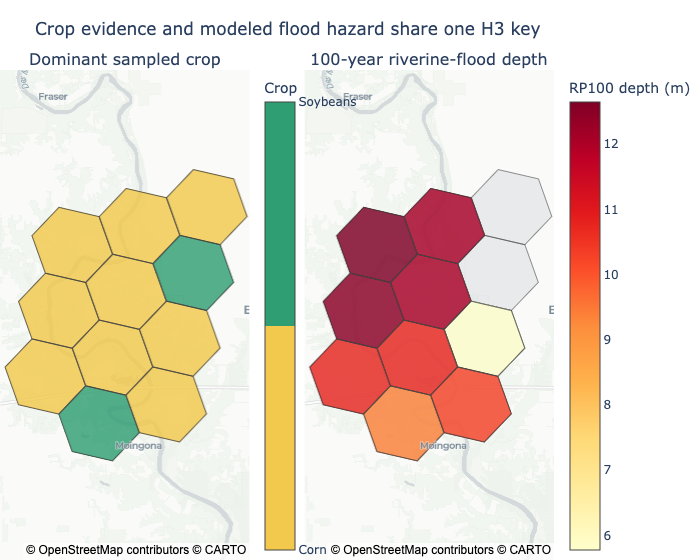

In [6]:
mapped = pq.read_table(map_path).to_pandas()
dominant = (mapped.sort_values('sampled_crop_share', ascending=False)
            .drop_duplicates('cell_index').copy())
dominant['cell_id'] = dominant['cell_index'].astype(str)
dominant['crop_index'] = dominant['crop_name'].map({'Corn': 0, 'Soybeans': 1})
features = []
for cell in dominant['cell_index']:
    boundary = h3.cell_to_boundary(h3.int_to_str(int(cell)))
    coordinates = [[lon, lat] for lat, lon in boundary]
    coordinates.append(coordinates[0])
    features.append({'type': 'Feature', 'id': str(cell), 'properties': {},
                     'geometry': {'type': 'Polygon', 'coordinates': [coordinates]}})
hex_geojson = {'type': 'FeatureCollection', 'features': features}
custom = dominant[['crop_name', 'sampled_crop_share', 'pixel_count',
                   'value_rp10', 'value_rp100', 'hazard_coverage']].to_numpy()
center = {'lon': (BOUNDS[0] + BOUNDS[2]) / 2,
          'lat': (BOUNDS[1] + BOUNDS[3]) / 2}
fig = make_subplots(rows=1, cols=2,
    specs=[[{'type': 'map'}, {'type': 'map'}]],
    subplot_titles=('Dominant sampled crop', '100-year riverine-flood depth'))
fig.add_trace(go.Choroplethmap(
    geojson=hex_geojson, locations=dominant['cell_id'], z=dominant['crop_index'],
    colorscale=[[0, '#f2c94c'], [0.499, '#f2c94c'], [0.5, '#2f9e72'], [1, '#2f9e72']],
    zmin=0, zmax=1, marker_opacity=0.82, marker_line_width=1,
    colorbar={'title': 'Crop', 'tickvals': [0, 1],
              'ticktext': ['Corn', 'Soybeans'], 'x': 0.46},
    customdata=custom,
    hovertemplate='<b>%{customdata[0]}</b><br>sampled crop share %{customdata[1]:.0%}'
                  '<br>sampled pixels %{customdata[2]:,.0f}<extra></extra>'
), row=1, col=1)
fig.add_trace(go.Choroplethmap(
    geojson=hex_geojson, locations=dominant['cell_id'], z=[0] * len(dominant),
    colorscale=[[0, '#d9dde3'], [1, '#d9dde3']], showscale=False,
    marker_opacity=0.55, marker_line_width=1, hoverinfo='skip'
), row=1, col=2)
modeled = dominant[dominant['value_rp100'].notna()]
fig.add_trace(go.Choroplethmap(
    geojson=hex_geojson, locations=modeled['cell_id'], z=modeled['value_rp100'],
    colorscale='YlOrRd', marker_opacity=0.82, marker_line_width=1,
    colorbar={'title': 'RP100 depth (m)', 'x': 1.01},
    customdata=modeled[['crop_name', 'sampled_crop_share',
                        'value_rp10', 'value_rp100']].to_numpy(),
    hovertemplate='<b>%{customdata[0]}</b><br>sampled crop share %{customdata[1]:.0%}'
                  '<br>RP10 %{customdata[2]:.2f} m'
                  '<br>RP100 %{customdata[3]:.2f} m<extra></extra>'
), row=1, col=2)
fig.update_layout(
    title='Crop evidence and modeled flood hazard share one H3 key',
    height=560, margin={'l': 0, 'r': 0, 't': 70, 'b': 0},
    map={'style': 'carto-positron', 'center': center, 'zoom': 10.7},
    map2={'style': 'carto-positron', 'center': center, 'zoom': 10.7},
)
fig.show()

## 5. Compare coverage and return-period implications by crop

The first chart makes missing hazard coverage visible rather than silently dropping it. The second weights flood depth by sampled crop pixels within the modeled overlap; it is an exposure summary, not expected loss.

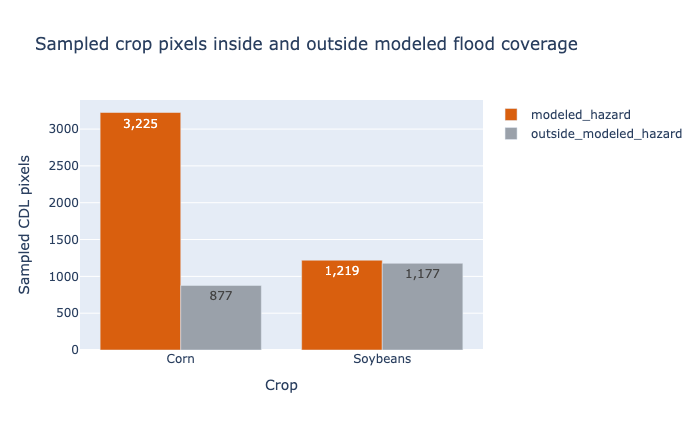

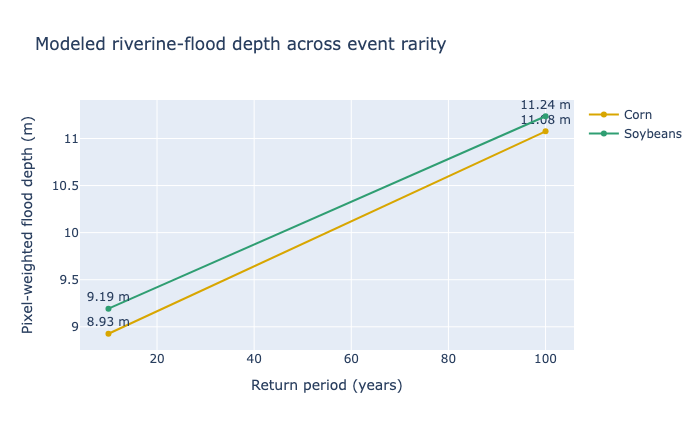

In [7]:
summary = pq.read_table(summary_path).to_pandas()
coverage_fig = px.bar(
    summary, x='crop_name', y='sampled_pixels', color='hazard_coverage',
    barmode='group', text_auto=',.0f',
    color_discrete_map={'modeled_hazard': '#d95f0e',
                        'outside_modeled_hazard': '#9aa1aa'},
    labels={'crop_name': 'Crop', 'sampled_pixels': 'Sampled CDL pixels',
            'hazard_coverage': 'Hazard coverage'},
    title='Sampled crop pixels inside and outside modeled flood coverage',
)
coverage_fig.update_layout(height=430, legend_title_text='')
coverage_fig.show()
evaluated = pq.read_table(evaluation_path).to_pandas()
long = evaluated.melt(
    id_vars=['crop_name', 'pixel_count'], value_vars=['value_rp10', 'value_rp100'],
    var_name='return_period', value_name='depth_m')
long['return_period_years'] = (long['return_period']
    .str.replace('value_rp', '', regex=False).astype(int))
weighted = (long.dropna(subset=['depth_m']).assign(weighted_depth=lambda d: d.depth_m * d.pixel_count)
            .groupby(['crop_name', 'return_period_years'], as_index=False)
            .agg(weighted_depth=('weighted_depth', 'sum'),
                 sampled_pixels=('pixel_count', 'sum')))
weighted['pixel_weighted_depth_m'] = (
    weighted['weighted_depth'] / weighted['sampled_pixels'])
depth_fig = px.line(
    weighted, x='return_period_years', y='pixel_weighted_depth_m',
    color='crop_name', markers=True, text='pixel_weighted_depth_m',
    color_discrete_map={'Corn': '#d8a600', 'Soybeans': '#2f9e72'},
    labels={'return_period_years': 'Return period (years)',
            'pixel_weighted_depth_m': 'Pixel-weighted flood depth (m)',
            'crop_name': 'Crop'},
    title='Modeled riverine-flood depth across event rarity',
)
depth_fig.update_traces(texttemplate='%{text:.2f} m', textposition='top center')
depth_fig.update_layout(height=430, legend_title_text='')
depth_fig.show()

## Reproducible outputs

- **[Download the layered crop + flood PMTiles archive](https://github.com/RiskThinking/crc-docs/blob/main/notebooks/artifacts/agricultural_crop_flood.pmtiles)** and open it in [pmtiles.io](https://pmtiles.io). Its `crop_flood` layer retains crop, sampled share, coverage status, and RP10/RP100 depth properties.
- The output directory also contains canonical GloFAS curves, agricultural units, hazard-covered evaluation candidates, the evaluation Parquet, map GeoParquet, summary Parquet, and a checksummed manifest.
- [`pipelines/agricultural_climate_pipeline.py`](https://github.com/RiskThinking/crc-docs/blob/main/pipelines/agricultural_climate_pipeline.py) is the headless twin.

Interpretation remains deliberately limited: sampled crop composition is not acreage or yield; modeled depth is not damage or loss; gray cells mean *outside this bounded modeled hazard support*, not zero flood risk.